# 02 · Binary classification of mutation positions

Follows the original `classification_model` notebook: load the dataset → explore the features → baseline models → hyperparameter search → final evaluation → ROC curves, confusion matrices and classification reports → feature importance.

**What changed from the original notebook**:
- all 844 residues are used (not 811);
- one 85/15 train/test split is replaced by **repeated nested cross-validation** (5 repeats × 10 outer folds, 5-fold inner grid search on ROC AUC), so every residue is scored by models that never saw it;
- median imputation, standardisation and ADASYN oversampling are fitted inside the training folds only (no PCA);
- predictions for the consensus vote come from these out-of-fold probabilities, not from models refitted on all residues.

In [1]:
%matplotlib inline
import sys, json, inspect, time, warnings
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from gaa_hotspot import data, network, stats, ml, figures as F
from gaa_hotspot import sss as sss_mod
from gaa_hotspot.common import AA, MODEL_ORDER, MODEL_NAMES, config, raw, read_processed, table, load_values
from gaa_hotspot.plotting import apply_style, MODEL_COLOURS, MODEL_LABELS, MODEL_SHORT, V7_MODEL_ORDER

apply_style()
plt.rcParams["figure.dpi"] = 80
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.precision", 4)
cfg = config()
V = load_values()
print("project root:", ROOT)

project root: Pompe-GAA-Hotspots


## 1. Loading the dataset

In [2]:
df_final = read_processed("residue_features.csv").set_index("residue")
print(df_final.shape)
df_final.head()

(844, 17)


,wt,degree,betweenness,closeness,burt,authority,page_rank,k_core,log_betweenness,areaSAS,areaSES,relSESA,kdhydro,phi,psi,conservation,mutation_observed
residue,,,,,,,,,,,,,,,,,
81,Q,4,62.4192,0.1032,0.3633,0.0002,0.0008,3,1.8022,175.4710,70.9262,106.534,-3.5,NaN,-20.1156,0.037,0
82,C,6,260.8814,0.1099,0.2848,0.0005,0.0011,4,2.4181,37.3313,31.1494,78.620,2.5,-108.1770,13.6793,-0.816,0
83,D,3,25.8998,0.1061,0.5180,0.0002,0.0007,3,1.4297,146.1407,80.4497,86.142,-3.5,-81.7587,69.5425,1.280,0
84,V,7,1363.6412,0.1184,0.2306,0.0009,0.0013,4,3.1350,20.2986,38.5642,90.264,4.2,-109.2543,125.9927,0.680,0
85,P,5,8.6444,0.1169,0.3883,0.0010,0.0009,4,0.9843,82.8478,59.8015,81.030,-1.6,-55.6090,141.9399,0.862,0


Distribution of target values (%):
 mutation_observed
0    74.64
1    25.36
Name: proportion, dtype: float64


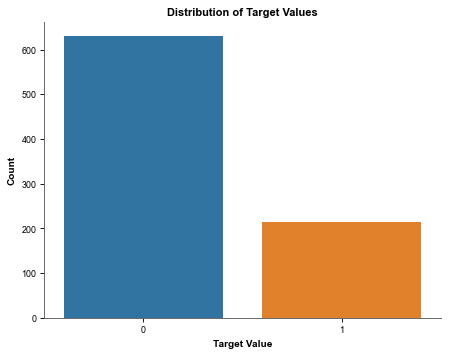

In [3]:
print("Distribution of target values (%):\n", df_final.mutation_observed.value_counts(normalize=True).mul(100).round(2))
sns.countplot(x="mutation_observed", data=df_final, hue="mutation_observed", legend=False)
plt.title("Distribution of Target Values"); plt.xlabel("Target Value"); plt.ylabel("Count"); plt.show()

Checking for null values (imputed inside the CV folds):

In [4]:
df_final.isnull().sum()[lambda s: s > 0]

phi    3
psi    2
dtype: int64

## 2. Difference of feature means between normal and known mutated residues

In [5]:
features = cfg["features"]
df_final[features].groupby(df_final["mutation_observed"]).mean().T.rename(columns={0: "no mutation", 1: "mutation"})

mutation_observed,no mutation,mutation
degree,7.8825,9.2710
log_betweenness,2.8232,3.2809
closeness,0.1436,0.1577
burt,0.2609,0.2006
authority,0.0992,0.1417
page_rank,0.0012,0.0013
k_core,4.8381,5.2897
kdhydro,-0.0197,-0.4626
areaSAS,41.0328,11.5412
areaSES,41.6768,22.4863


## 3. Distribution of each feature

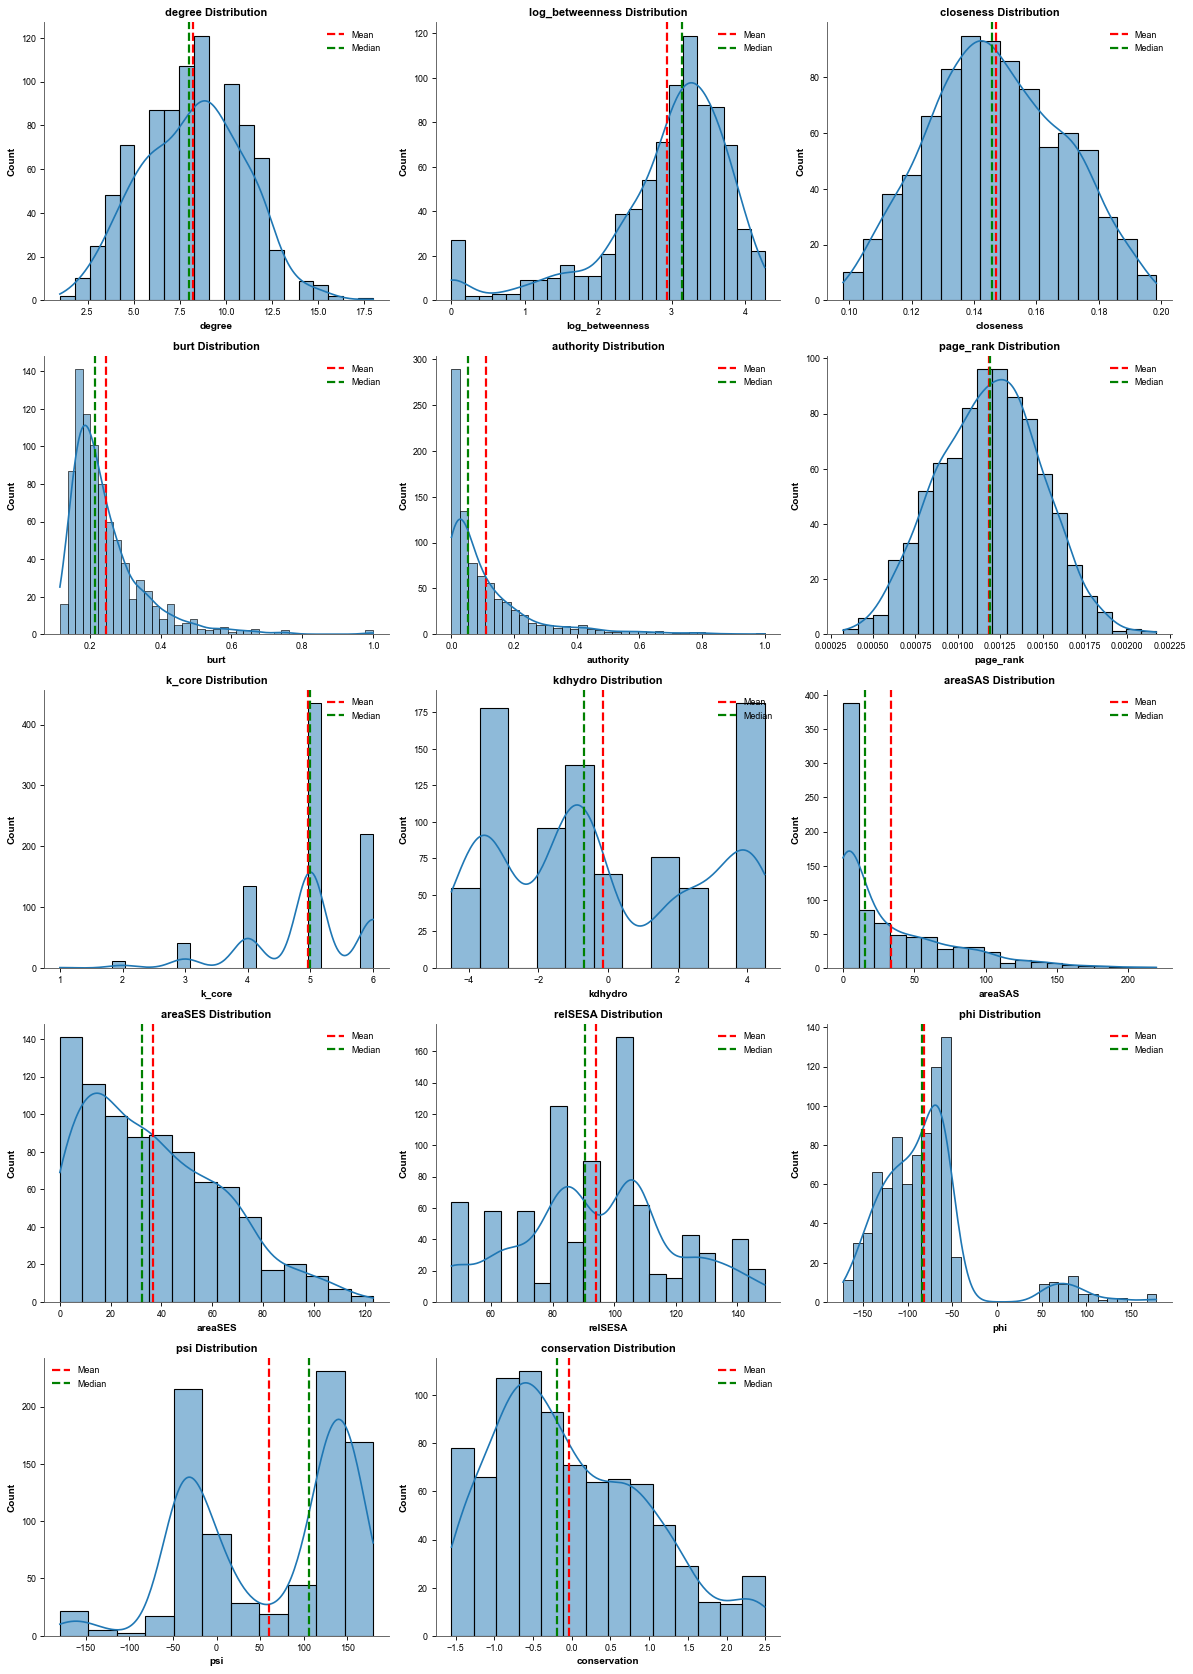

In [6]:
fig, axes = plt.subplots(5, 3, figsize=(15, 21)); axes = axes.ravel()
for ax, f in zip(axes, features):
    sns.histplot(df_final[f].dropna(), kde=True, ax=ax)
    ax.axvline(df_final[f].mean(), color="red", linestyle="dashed", linewidth=2, label="Mean")
    ax.axvline(df_final[f].median(), color="green", linestyle="dashed", linewidth=2, label="Median")
    ax.set_title(f"{f} Distribution"); ax.legend()
axes[-1].axis("off"); plt.tight_layout(); plt.show()

## 4. Dividing data into features and labels

In [7]:
X = df_final[features]
Y = df_final["mutation_observed"]
print(X.shape, Y.value_counts().to_dict())
X.describe().T

(844, 14) {0: 630, 1: 214}


,count,mean,std,min,25%,50%,75%,max
degree,844.0,8.2346,2.8035,1.0000e+00,6.0000,8.0000,10.0000,18.0000
log_betweenness,844.0,2.9392,0.8862,0.0000e+00,2.6166,3.1438,3.5267,4.2692
closeness,844.0,0.1471,0.0213,9.8092e-02,0.1316,0.1457,0.1631,0.1984
burt,844.0,0.2456,0.1063,1.1576e-01,0.1757,0.2138,0.2801,1.0000
authority,844.0,0.1100,0.1464,3.7244e-05,0.0156,0.0535,0.1440,1.0000
page_rank,844.0,0.0012,0.0003,3.2287e-04,0.0010,0.0012,0.0014,0.0022
k_core,844.0,4.9526,0.8822,1.0000e+00,5.0000,5.0000,6.0000,6.0000
kdhydro,844.0,-0.1320,2.9038,-4.5000e+00,-3.2750,-0.7000,2.8000,4.5000
areaSAS,844.0,33.5551,41.8077,-4.2600e-14,1.6970,15.0774,54.9057,219.7970
areaSES,844.0,36.8109,27.2131,0.0000e+00,14.4664,32.4967,56.2538,123.3342


## 5. Baseline models without hyperparameter tuning

**Why one train/test split is not enough.** The original notebook evaluated each model on a single 85/15 split (122 test residues). Repeating that split with 20 different random seeds shows how much a single split moves the AUC:

In [8]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict, ParameterGrid
from sklearn.metrics import roc_auc_score, roc_curve, auc, confusion_matrix, classification_report
aucs = []
for seed in range(20):
    X_tr, X_te, y_tr, y_te = train_test_split(X, Y, test_size=0.15, stratify=Y, random_state=seed)
    pipe = ml.make_pipeline("lr", cfg["seed"]).fit(X_tr, y_tr)
    aucs.append(roc_auc_score(y_te, pipe.predict_proba(X_te)[:, 1]))
print(f"logistic regression, default settings, 20 different 85/15 splits: AUC {np.mean(aucs):.3f} ± {np.std(aucs):.3f}  (range {min(aucs):.3f}-{max(aucs):.3f})")

logistic regression, default settings, 20 different 85/15 splits: AUC 0.800 ± 0.040  (range 0.733-0.853)


Untuned baseline models evaluated by 10-fold stratified cross-validation (imputation → scaling → ADASYN → model, fitted on the training folds):

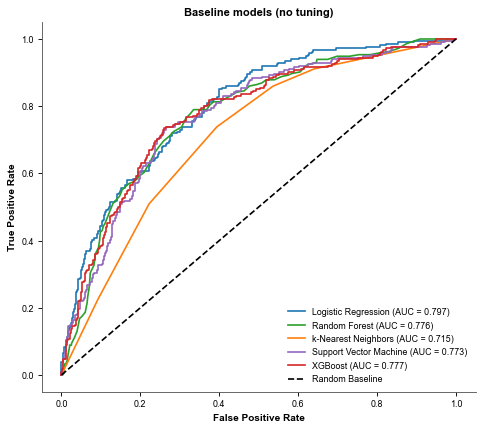

,model,untuned 10-fold CV AUC
0,Logistic Regression,0.7973
1,Random Forest,0.7760
2,k-Nearest Neighbors,0.7147
3,Support Vector Machine,0.7728
4,XGBoost,0.7767


In [9]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=cfg["seed"])
plt.figure(figsize=(7, 6))
base = []
for m in V7_MODEL_ORDER:
    p = cross_val_predict(ml.make_pipeline(m, cfg["seed"], probability=True), X, Y, cv=cv, method="predict_proba")[:, 1]
    fpr, tpr, _ = roc_curve(Y, p)
    plt.plot(fpr, tpr, color=MODEL_COLOURS[m], label=f"{MODEL_LABELS[m]} (AUC = {auc(fpr, tpr):.3f})")
    base.append({"model": MODEL_LABELS[m], "untuned 10-fold CV AUC": auc(fpr, tpr)})
plt.plot([0, 1], [0, 1], "k--", label="Random Baseline")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.title("Baseline models (no tuning)"); plt.legend(loc="lower right"); plt.show()
pd.DataFrame(base)

## 6. Hyperparameter search spaces

Same grids as the original `params` dictionary. kNN `algorithm`/`leaf_size` only change the neighbour-search implementation, so they are not searched; the random forest grid (864 combinations) is sampled with 60 random configurations.

In [10]:
for m in MODEL_ORDER:
    n = len(ParameterGrid(ml.GRIDS[m]))
    extra = f"  (randomised search: {cfg['ml']['rf_random_search_iter']} sampled)" if m == "rf" else ""
    print(f"{MODEL_NAMES[m]:22s} {n:4d} configurations{extra}\n    {ml.GRIDS[m]}")

Logistic regression      48 configurations
    [{'penalty': ['l1', 'l2'], 'C': [0.1, 1, 10, 100], 'solver': ['liblinear', 'saga'], 'max_iter': [100, 200, 500]}]
Random forest           864 configurations  (randomised search: 60 sampled)
    {'n_estimators': [100, 200, 300], 'criterion': ['gini', 'entropy'], 'max_depth': [None, 10, 20, 30], 'min_samples_split': [2, 5, 10], 'min_samples_leaf': [1, 2, 4], 'max_features': ['sqrt', 'log2'], 'bootstrap': [True, False]}
Support vector machine   24 configurations
    [{'C': [0.1, 1, 10, 100], 'kernel': ['linear', 'rbf', 'sigmoid']}, {'C': [0.1, 1, 10, 100], 'kernel': ['poly'], 'degree': [3, 4, 5]}]
XGBoost                  36 configurations
    {'n_estimators': [100, 200], 'learning_rate': [0.01, 0.1, 0.2], 'max_depth': [3, 6, 9], 'subsample': [0.8, 1.0]}
k-nearest neighbours     20 configurations
    {'n_neighbors': [3, 5, 7, 10, 20], 'weights': ['uniform', 'distance'], 'p': [1, 2]}


## 7. Repeated nested cross-validation

The pipeline and the nested-CV loop used by `scripts/03_train_models.py`:

In [11]:
print(inspect.getsource(ml.make_pipeline)); print(inspect.getsource(ml.tune)); print(inspect.getsource(ml.nested_cv))

def make_pipeline(name: str, seed: int, params: dict | None = None, probability: bool = False) -> Pipeline:
    est = base_estimator(name, seed)
    if params:
        est.set_params(**params)
    if name == "svm" and probability:
        est.set_params(probability=True)
    return Pipeline(
        [
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
            ("adasyn", ADASYN(random_state=seed)),
            ("model", est),
        ]
    )

def tune(name: str, X: np.ndarray, y: np.ndarray, seed: int, inner_folds: int, rf_iter: int, n_jobs: int) -> tuple[dict, float]:
    """Inner-loop hyperparameter search; returns best parameters and inner CV AUC."""
    cv = StratifiedKFold(n_splits=inner_folds, shuffle=True, random_state=seed)
    pipe = make_pipeline(name, seed)
    grid = _prefixed(GRIDS[name])
    if name == "rf":
        search = RandomizedSearchCV(pipe, grid, n_iter=rf_iter, scoring="roc_auc", cv=cv, random_state=seed, n_jobs

The full run (5 models × 5 repeats × 10 outer folds) takes about 45 minutes, so the notebook loads its stored output. Set `RUN_FULL_NESTED_CV = True` to recompute it here.

In [12]:
RUN_FULL_NESTED_CV = False
mc = cfg["ml"]
if RUN_FULL_NESTED_CV:
    long, params = ml.nested_cv(X, Y, MODEL_ORDER, mc["outer_folds"], mc["outer_repeats"], mc["inner_folds"], cfg["seed"], mc["rf_random_search_iter"], -1)
else:
    long = read_processed("oof_predictions_long.csv")
    params = pd.read_csv(table("selected_hyperparameters.csv"))
print("out-of-fold predictions:", long.shape, "  selected hyperparameters:", params.shape)
long.head()

out-of-fold predictions: (21100, 6)   selected hyperparameters: (250, 6)


,repeat,fold,model,residue,y,probability
0,0,0,lr,89,1,0.6898
1,0,0,lr,94,0,0.7740
2,0,0,lr,95,0,0.4340
3,0,0,lr,99,0,0.3646
4,0,0,lr,107,0,0.5494


**Reproducibility check:** rerun the first repeat for logistic regression and kNN here and compare with the stored probabilities.

In [13]:
t0 = time.time()
demo, demo_params = ml.nested_cv(X, Y, ["lr", "knn"], mc["outer_folds"], 1, mc["inner_folds"], cfg["seed"], mc["rf_random_search_iter"], -1, log=lambda *a: None)
ref = long[(long.repeat == 0) & long.model.isin(["lr", "knn"])]
cmp = demo.merge(ref, on=["model", "residue"], suffixes=("_rerun", "_stored"))
print(f"rerun took {time.time() - t0:.0f} s; max |rerun - stored| probability = {(cmp.probability_rerun - cmp.probability_stored).abs().max():.2e}")

rerun took 6 s; max |rerun - stored| probability = 1.11e-16


Hyperparameters selected in the 50 outer folds:

In [14]:
display(params.groupby("model")[["inner_cv_auc", "outer_fold_auc"]].agg(["mean", "std"]).round(3))
params.groupby("model").params.agg(lambda s: f"{s.value_counts().iloc[0]}/{len(s)} folds: {s.value_counts().index[0]}").to_frame("most frequently selected")

inner_cv_auc        outer_fold_auc       
              mean    std           mean    std
model                                          
knn          0.764  0.011          0.763  0.050
lr           0.802  0.008          0.801  0.055
rf           0.788  0.009          0.786  0.051
svm          0.796  0.007          0.791  0.054
xgb          0.788  0.009          0.779  0.052

,most frequently selected
model,
knn,"33/50 folds: {""n_neighbors"": 20, ""p"": 1, ""weig..."
lr,"20/50 folds: {""C"": 0.1, ""max_iter"": 100, ""pena..."
rf,"7/50 folds: {""n_estimators"": 100, ""min_samples..."
svm,"25/50 folds: {""C"": 0.1, ""kernel"": ""linear""}"
xgb,"16/50 folds: {""learning_rate"": 0.01, ""max_dept..."


## 8. ROC curve of each model

Each residue's probability is the mean of its 5 out-of-fold predictions (one per repeat).

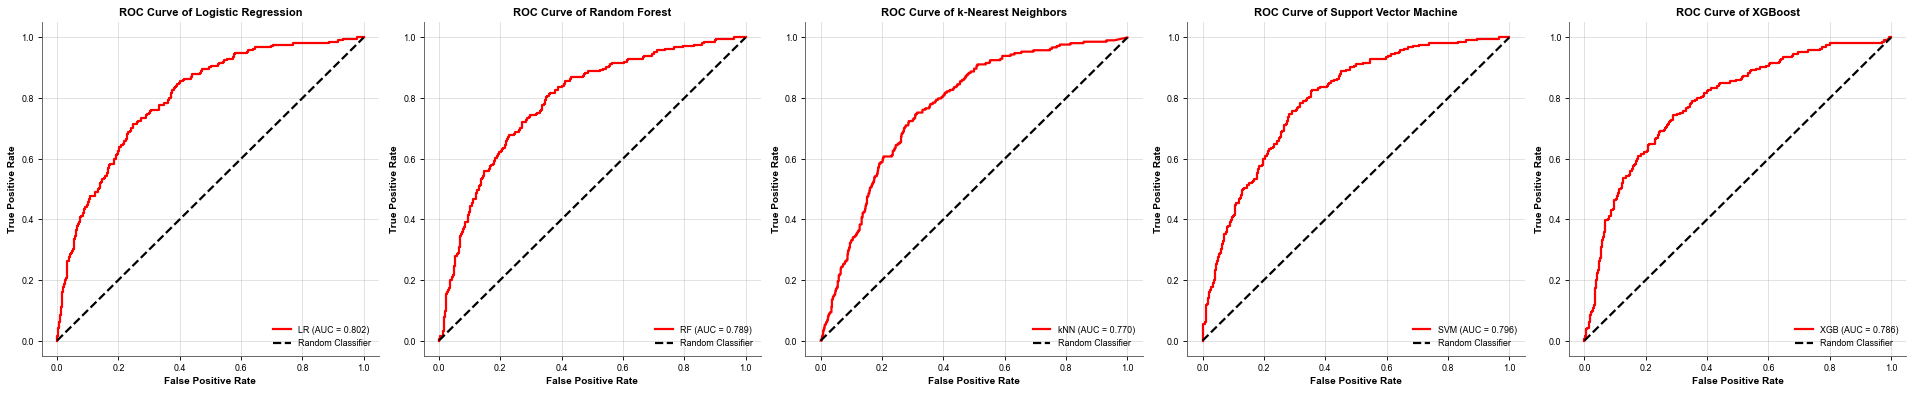

In [15]:
prob = read_processed("oof_probabilities.csv").set_index("residue")
yv = prob.mutation_observed.values
fig, axes = plt.subplots(1, 5, figsize=(24, 5))
for ax, m in zip(axes, V7_MODEL_ORDER):
    fpr, tpr, _ = roc_curve(yv, prob[m])
    ax.plot(fpr, tpr, color="red", lw=2, label=f"{MODEL_SHORT[m]} (AUC = {auc(fpr, tpr):.3f})")
    ax.plot([0, 1], [0, 1], color="black", lw=2, linestyle="--", label="Random Classifier")
    ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate"); ax.set_title(f"ROC Curve of {MODEL_LABELS[m]}")
    ax.legend(loc="lower right"); ax.grid(alpha=0.4)
plt.tight_layout(); plt.show()

### Figure 4a — all models

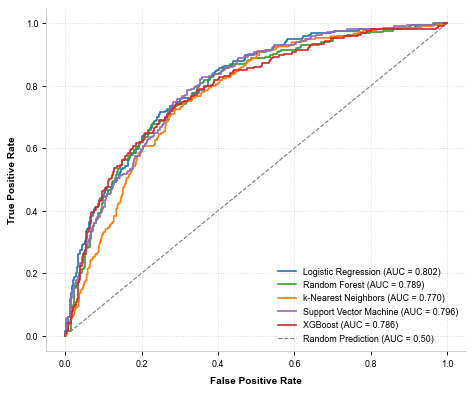

In [16]:
F.fig4a_roc(prob)
plt.show()

### Supplementary Figure S4 — mean ± SD ROC across the 50 outer folds

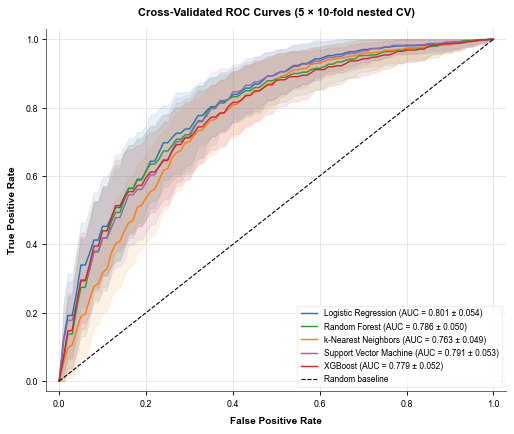

In [17]:
F.figS_cv_roc(long)
plt.show()

## 9. Performance and DeLong comparisons

Pooled out-of-fold AUC with DeLong 95% CI, recomputed here and compared with `model_performance.csv`:

In [18]:
rows = []
for m in V7_MODEL_ORDER:
    a, lo, hi = stats.delong_ci(yv, prob[m].values)
    rows.append({"model": MODEL_LABELS[m], "pooled OOF AUC": a, "95% CI low": lo, "95% CI high": hi,
                 "fold AUC mean": params.loc[params.model == m, "outer_fold_auc"].mean(), "fold AUC SD": params.loc[params.model == m, "outer_fold_auc"].std()})
display(pd.DataFrame(rows).sort_values("pooled OOF AUC", ascending=False))
pd.read_csv(table("delong_comparisons.csv"))

,model,pooled OOF AUC,95% CI low,95% CI high,fold AUC mean,fold AUC SD
0,Logistic Regression,0.8024,0.7697,0.8352,0.8014,0.0545
3,Support Vector Machine,0.7959,0.7631,0.8286,0.7911,0.0536
1,Random Forest,0.7885,0.7541,0.8230,0.7857,0.0509
4,XGBoost,0.7858,0.7504,0.8212,0.7791,0.0522
2,k-Nearest Neighbors,0.7702,0.7358,0.8047,0.7631,0.0500


,comparison,model_a,model_b,auc_a,auc_b,difference,z,p,p_holm
0,Logistic regression vs Random forest,lr,rf,0.8024,0.7885,0.0139,1.6158,0.1061,0.2123
1,Logistic regression vs Support vector machine,lr,svm,0.8024,0.7959,0.0066,1.1801,0.2380,0.2380
2,Logistic regression vs XGBoost,lr,xgb,0.8024,0.7858,0.0166,1.9278,0.0539,0.1616
3,Logistic regression vs k-nearest neighbours,lr,knn,0.8024,0.7702,0.0322,2.6098,0.0091,0.0362


## 10. Confusion matrices and classification reports

Two cut-offs per model: probability ≥ 0.5, and the model's 90%-specificity threshold used for the consensus vote (notebook 03). Because ADASYN balances the training classes, the models are calibrated to 50% prevalence and a 0.5 cut-off flags about a third of all unannotated residues.

In [19]:
thresholds = pd.read_csv(table("vote_thresholds.csv")).set_index("model")["threshold"].to_dict()
for m in V7_MODEL_ORDER:
    for name, thr in [("probability >= 0.5", 0.5), ("90% specificity", thresholds[m])]:
        pred = (prob[m] >= thr).astype(int)
        print(f"===== {MODEL_LABELS[m]} | {name} (threshold {thr:.3f})")
        print(pd.DataFrame(confusion_matrix(yv, pred), index=["true: no mutation", "true: mutation"], columns=["pred: no mutation", "pred: mutation"]))
        print(classification_report(yv, pred, target_names=["No mutation", "Mutation"], digits=3))

===== Logistic Regression | probability >= 0.5 (threshold 0.500)
                   pred: no mutation  pred: mutation
true: no mutation                403             227
true: mutation                    46             168
              precision    recall  f1-score   support

 No mutation      0.898     0.640     0.747       630
    Mutation      0.425     0.785     0.552       214

    accuracy                          0.677       844
   macro avg      0.661     0.712     0.649       844
weighted avg      0.778     0.677     0.697       844

===== Logistic Regression | 90% specificity (threshold 0.713)
                   pred: no mutation  pred: mutation
true: no mutation                567              63
true: mutation                   118              96
              precision    recall  f1-score   support

 No mutation      0.828     0.900     0.862       630
    Mutation      0.604     0.449     0.515       214

    accuracy                          0.786       844
   macro a

### Supplementary Figure S3 — confusion matrices

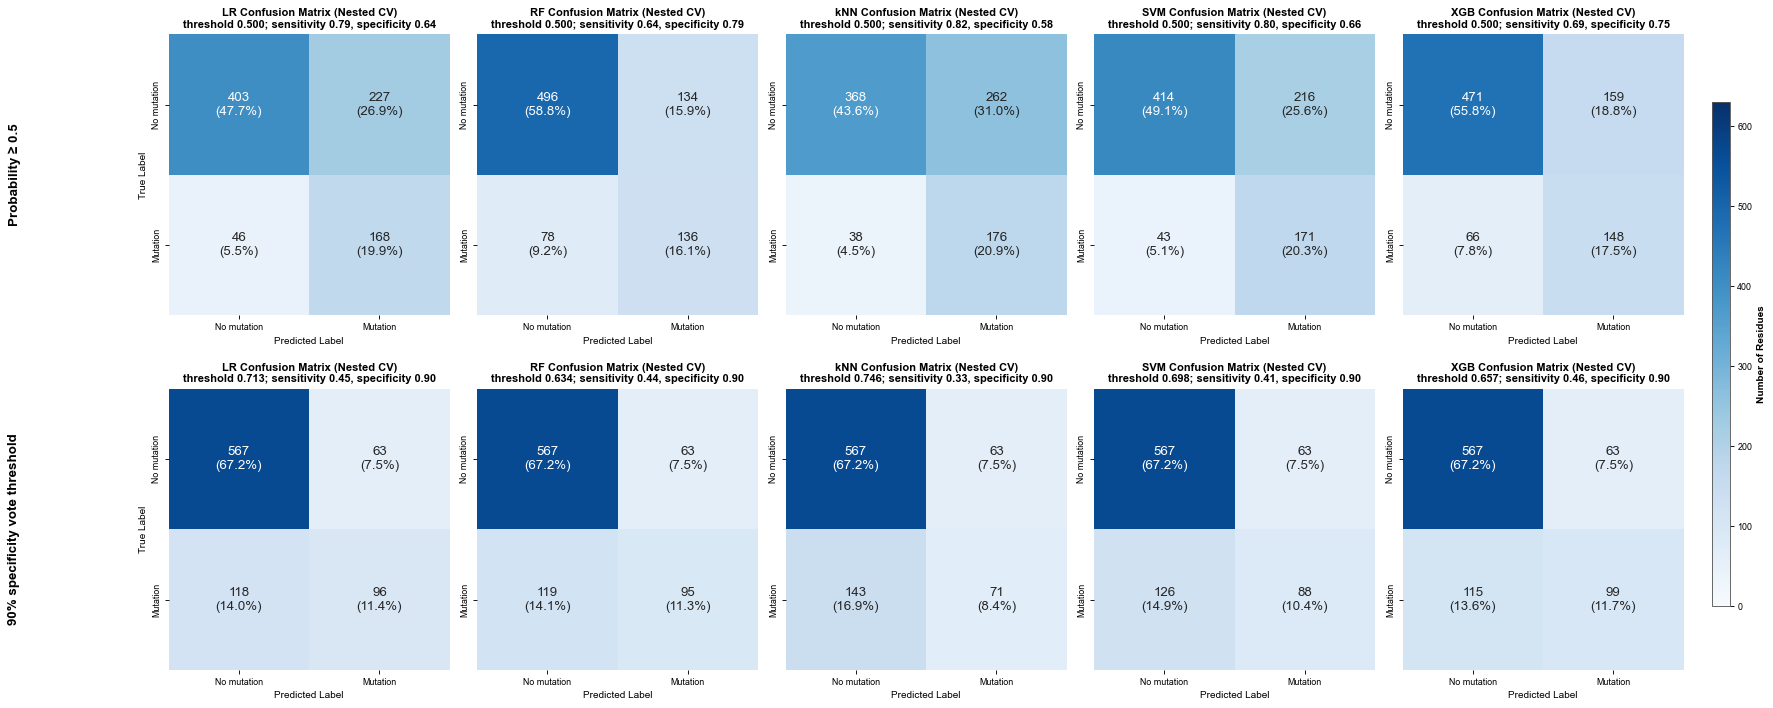

In [20]:
F.figS_confusion(prob, thresholds)
plt.show()

### Supplementary Figure S2 — accuracy, F1, AUC and balanced accuracy per outer fold (mean ± SD, threshold 0.5)

accuracy            f1        roc_auc        balanced_accuracy       
          mean    std   mean    std    mean    std              mean    std
model                                                                      
knn      0.641  0.046  0.539  0.044   0.763  0.050             0.702  0.043
lr       0.680  0.043  0.556  0.048   0.801  0.055             0.716  0.046
rf       0.748  0.040  0.561  0.071   0.786  0.051             0.712  0.055
svm      0.693  0.050  0.565  0.057   0.791  0.054             0.723  0.051
xgb      0.718  0.052  0.554  0.060   0.779  0.052             0.709  0.051

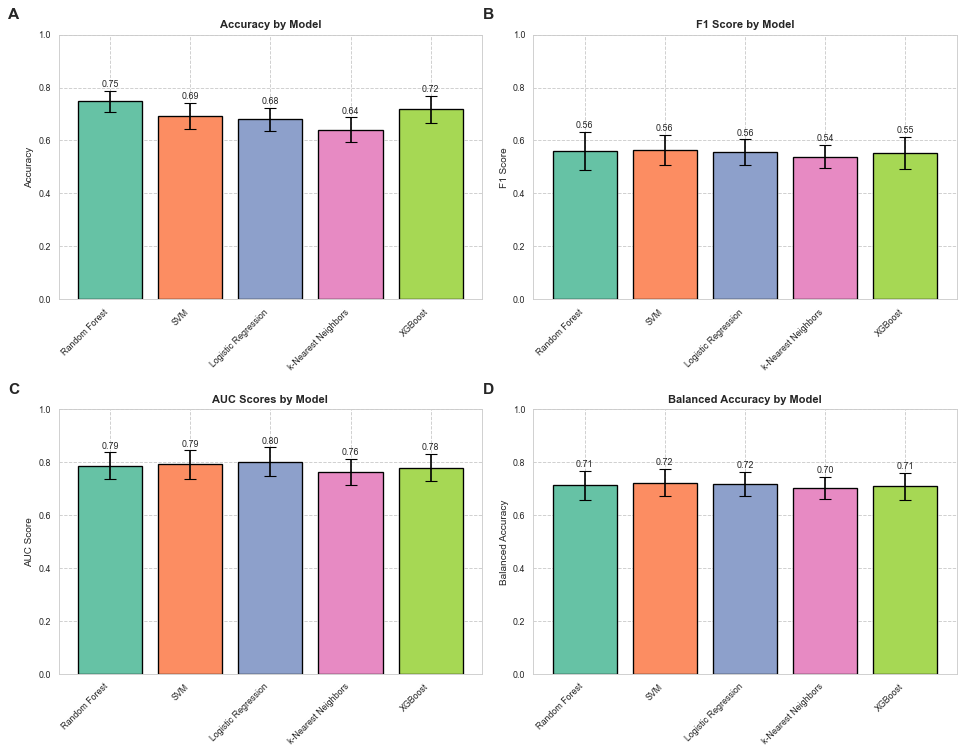

In [21]:
fm = F.fold_metrics(long, cfg["ml"]["vote_threshold"])
display(fm.groupby("model")[["accuracy", "f1", "roc_auc", "balanced_accuracy"]].agg(["mean", "std"]).round(3))
F.figS_model_metrics(fm)
plt.show()

## 11. Feature importance

Permutation importance: drop in held-out ROC AUC when one feature is shuffled in the test fold (first CV repeat, 20 permutations).

,lr,rf,svm,xgb,knn,mean_across_models,rank
feature,,,,,,,
conservation,0.1551,0.1061,0.1095,0.1414,0.0358,0.1096,1
kdhydro,0.0196,0.0174,0.0150,0.0180,0.0259,0.0192,2
areaSAS,0.0218,0.0252,0.0093,0.0252,0.0122,0.0187,3
areaSES,0.0125,0.0055,0.0235,0.0011,0.0118,0.0109,4
closeness,0.0094,0.0039,0.0176,0.0026,0.0055,0.0078,5
authority,0.0131,0.0050,0.0108,0.0010,0.0089,0.0078,6
k_core,0.0047,0.0045,0.0036,0.0036,0.0096,0.0052,7
relSESA,0.0010,0.0059,0.0052,0.0034,0.0044,0.0040,8
burt,0.0089,0.0007,0.0032,0.0001,-0.0013,0.0023,9


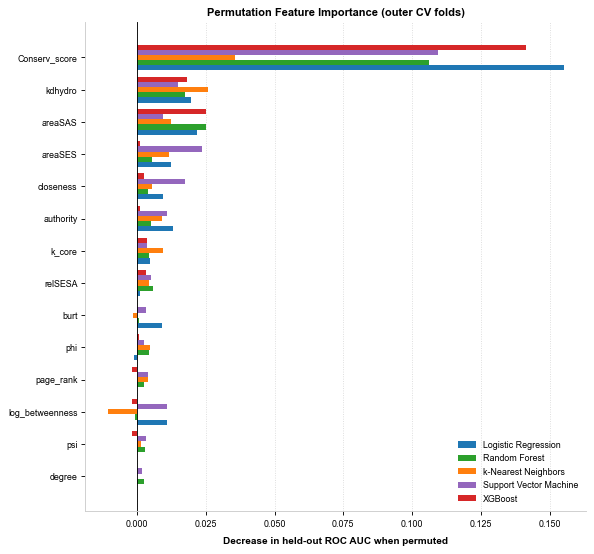

In [22]:
pi = pd.read_csv(table("permutation_importance.csv")).set_index("feature")
display(pi.round(4))
F.figS_permutation_importance(pi)
plt.show()

SHAP values of the models refitted on all residues (interpretation only, not used for evaluation):

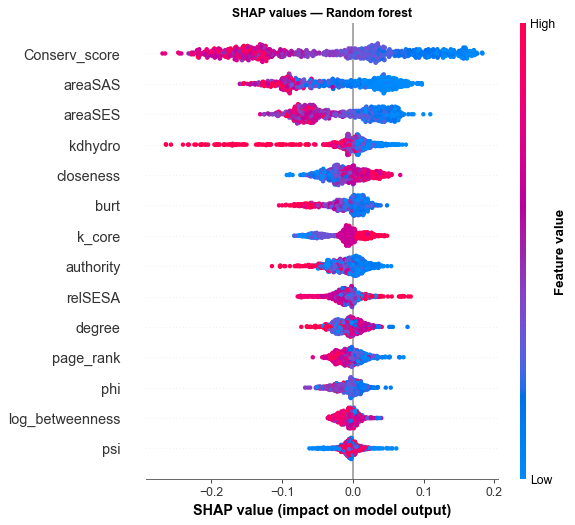

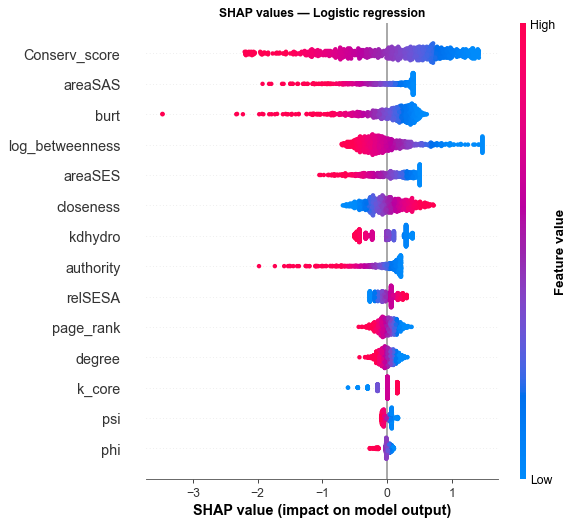

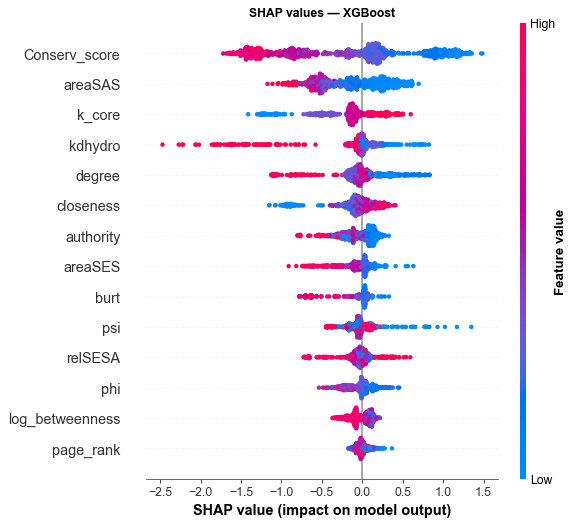

In [23]:
for m in ["rf", "lr", "xgb"]:
    sv = read_processed(f"shap_values_{m}.csv").set_index("residue")
    xin = read_processed(f"shap_inputs_{m}.csv").set_index("residue")[sv.columns]
    F.figS_shap(sv, xin, f"SHAP values — {MODEL_NAMES[m]}")
    plt.show()

## 12. Feature-group ablation

How much each feature group contributes (nested CV, 2 repeats):

,feature_set,n_features,model,pooled_oof_auc,auc_ci_low,auc_ci_high,delong_p_vs_all
0,Conservation only,1,lr,0.7915,0.7575,0.8254,0.2776
1,Conservation only,1,xgb,0.7615,0.7257,0.7974,0.1415
2,Network only,7,lr,0.7125,0.6740,0.7511,0.0000
3,Network only,7,xgb,0.7052,0.6669,0.7436,0.0001
4,Structure only,6,lr,0.7649,0.7297,0.8001,0.0011
5,Structure only,6,xgb,0.7652,0.7291,0.8013,0.2090
6,Structure + conservation,7,lr,0.7994,0.7661,0.8326,0.8569
7,Structure + conservation,7,xgb,0.7836,0.7477,0.8194,0.6698
8,Network + conservation,8,lr,0.7941,0.7608,0.8274,0.2983
9,Network + conservation,8,xgb,0.7716,0.7366,0.8065,0.4425


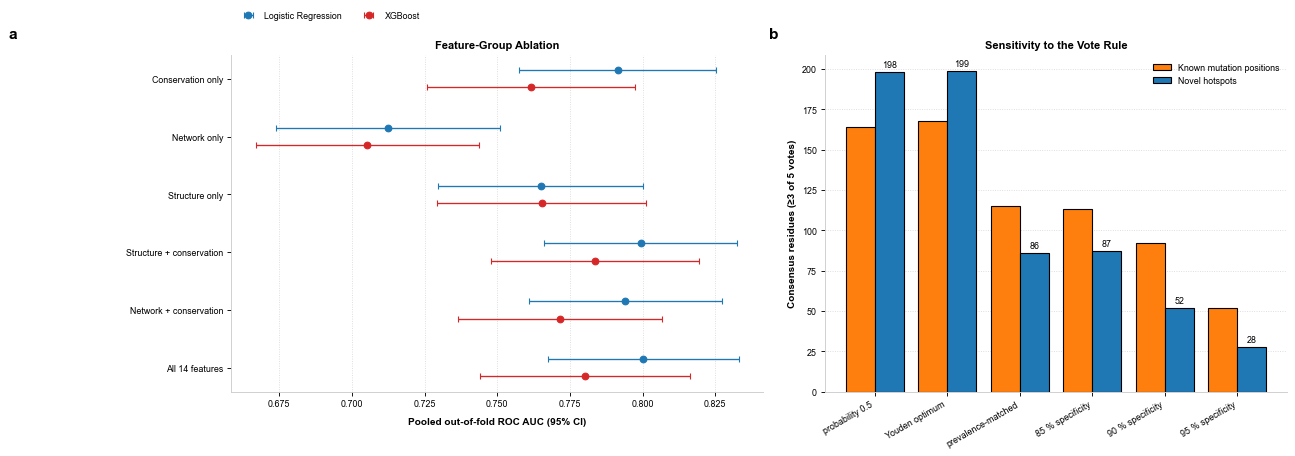

In [24]:
ab = pd.read_csv(table("feature_ablation.csv"))
display(ab.round(4))
F.figS_ablation_vote_rule(ab, pd.read_csv(table("vote_threshold_sensitivity.csv")))
plt.show()

## 13. Sensitivity analysis: the original 811-residue subset

,844 residues,811 residues
model,,
lr,0.802,0.796
rf,0.789,0.780
svm,0.796,0.794
xgb,0.786,0.779
knn,0.770,0.761


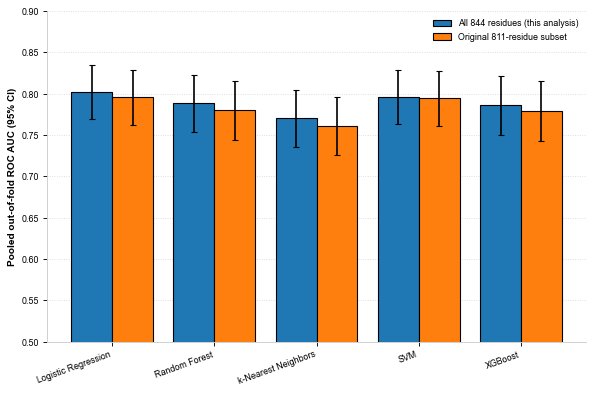

In [25]:
lp = pd.read_csv(table("legacy811_model_performance.csv")).set_index("model")
perf = pd.read_csv(table("model_performance.csv")).set_index("model")
display(pd.DataFrame({"844 residues": perf.pooled_oof_auc, "811 residues": lp.pooled_oof_auc}).round(3))
F.figS_legacy811(perf, lp)
plt.show()